In [1]:
import sys
import os
sys.path.append(os.path.abspath('../../'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from functions.preproc import *
from functions.cox import *

from sklearn import set_config
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import make_scorer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sksurv.metrics import integrated_brier_score
from sksurv.metrics import concordance_index_ipcw
from sksurv.nonparametric import kaplan_meier_estimator
from sklearn.inspection import permutation_importance
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import IsolationForest

from sksurv.metrics import concordance_index_censored
from sksurv.util import Surv
from sksurv.linear_model import CoxnetSurvivalAnalysis, CoxPHSurvivalAnalysis

import jinja2

import time
set_config(display="text")  # displays text representation of estimators

In [2]:
dataset = pd.read_csv("../data_treated_nopr.csv")

diagnosis_variables = []
with open("../diagnosis.txt", "r") as file:
    for line in file:
        diagnosis_variables.append(line.strip())

treatment_variables = []
with open("../treatment.txt", "r") as file:
    for line in file:
        treatment_variables.append(line.strip())

survival_dataset = dataset.drop('Unnamed: 0', axis=1)

feature_columns = treatment_variables + diagnosis_variables

In [4]:
# Find duplicated patients with regional ln recurrence = 1
mask = (survival_dataset.duplicated(subset='PERSON_ID', keep=False)) #& (survival_dataset['Regional LN recurrence'] == 1)

# For each duplicated PERSON_ID with recurrence, keep only the row with the lowest survival days
to_remove = (
    survival_dataset[mask]
    .sort_values(['PERSON_ID', 'Survival days'], ascending=[True, True])
    .groupby('PERSON_ID')
    .head(-1)
    .index
)

survival_dataset = survival_dataset.drop(to_remove)

In [5]:
# Prepare data
data_x = survival_dataset[feature_columns]

data_y = Surv.from_arrays(
    event=survival_dataset['Regional LN recurrence'],
    time=survival_dataset['Survival days']
)
# Since every duplicated patient has a consistent event indicator (regional ln recurrence) I can use this method
groups = survival_dataset['PERSON_ID']
event_indicator = survival_dataset['Regional LN recurrence']

In [6]:
sgkf = StratifiedKFold(n_splits=5, shuffle=True, random_state=12)
cv = sgkf.split(X=data_x, y=survival_dataset['Regional LN recurrence'])

train_index, test_index = next(cv)

In [7]:
for train_idx, val_idx in cv:
    print("Train events:", survival_dataset.iloc[train_idx]["Regional LN recurrence"].sum())
    print("Val events:", survival_dataset.iloc[val_idx]["Regional LN recurrence"].sum())

Train events: 27.0
Val events: 6.0
Train events: 26.0
Val events: 7.0
Train events: 26.0
Val events: 7.0
Train events: 26.0
Val events: 7.0


In [8]:
print("Train events:", survival_dataset.iloc[train_index]["Regional LN recurrence"].sum())
print("Val events:", survival_dataset.iloc[test_index]["Regional LN recurrence"].sum())

Train events: 27.0
Val events: 6.0


In [ ]:
fitter_data = survival_dataset.iloc[train_index]
fitter_test = survival_dataset.iloc[test_index]

In [271]:
columns=['Survival days', 'Regional LN recurrence', 'Total administered dose', 'Age', 'Ki67 positive cells (%) at CB', 'Oestrogen receptor status at CB_1.0']
fit_data = fitter_data[columns]
fit_test = fitter_test[columns]

In [244]:
from lifelines import CoxPHFitter

cph = CoxPHFitter()
cph.fit(fit_data, duration_col='Survival days', event_col='Regional LN recurrence')

<lifelines.CoxPHFitter: fitted with 2376 total observations, 2349 right-censored observations>

In [232]:
# Get exp(Xβ) risk scores (relative risk)
risk_scores_train = cph.predict_partial_hazard(fit_data)
risk_scores_test = cph.predict_partial_hazard(fit_test)

In [233]:
indexs = fit_data[fit_data['Regional LN recurrence'] == 1].index

In [234]:
indexs

Index([ 258,  410,  661,  810,  861,  867,  927,  933, 1076, 1135, 1187, 1217,
       1282, 1315, 1412, 1487, 1548, 1764, 1856, 1962, 2052, 2124, 2161, 2351,
       2372, 2482, 2609],
      dtype='int64')

In [235]:
risk_scores_train[indexs]

258     20.318291
410      0.668745
661      1.040999
810      2.096607
861      0.705081
867      0.615629
927      4.022065
933      2.368336
1076     4.875487
1135     2.672849
1187    17.771968
1217     5.967092
1282     4.579905
1315     2.385487
1412    11.398117
1487     2.094931
1548     0.538279
1764     3.308241
1856     2.334403
1962     4.329933
2052    20.613638
2124     2.557834
2161    13.262996
2351    19.193961
2372     0.719934
2482     1.963207
2609     1.921166
dtype: float64

In [288]:
columns = ['Total administered dose', 'Age', 'Ki67 positive cells (%) at CB', 'Oestrogen receptor status at CB_1.0']
x_train_iso = x_train[columns]

In [294]:
# fit an isolation forest to flag weird patients
iso = IsolationForest(contamination=0.01, random_state=42)
iso.fit(x_train_iso)

IsolationForest(contamination=0.01, random_state=42)

In [296]:
# now score everyone and see who gets flagged
outlier_flags = iso.predict(x_train_iso)
flags = outlier_flags == -1
fit_data[flags]

,Survival days,Regional LN recurrence,Total administered dose,Age,Ki67 positive cells (%) at CB,Oestrogen receptor status at CB_1.0
97,537.0,0.0,0.0,31.0,90.0,1.0
153,401.0,0.0,0.0,86.0,60.0,1.0
265,417.0,0.0,0.0,82.0,60.0,1.0
467,1379.0,0.0,0.0,86.0,90.0,1.0
773,1881.0,0.0,0.0,52.0,90.0,1.0
796,556.0,0.0,0.0,86.0,70.0,1.0
826,1204.0,0.0,50.0,32.0,95.0,0.0
894,211.0,0.0,0.0,84.0,25.0,1.0
1239,1108.0,0.0,20.0,31.0,80.0,1.0
1293,1885.0,0.0,0.0,33.0,80.0,1.0


In [133]:
import jinja2
cph.print_summary()

<lifelines.CoxPHFitter: fitted with 2376 total observations, 2349 right-censored observations>
             duration col = 'Survival days'
                event col = 'Regional LN recurrence'
      baseline estimation = breslow
   number of observations = 2376
number of events observed = 27
   partial log-likelihood = -169.26
         time fit was run = 2025-07-29 17:08:13 UTC

---
                                     coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                            
Total administered dose             -0.03      0.97      0.01           -0.05           -0.01                0.95                0.99
Age                                 -0.01      0.99      0.02           -0.04            0.02                0.96                1.02
Ki67 positive cells (%) at CB       -0.01      0.99      0.01           -0.03            0.01                0.97                1.01
Oestrogen receptor status at CB_1.0  2.16      8.65      0.44            1.30            3.01                3.68               20.30

                                     cmp to     z      p  -log2(p)
covariate                                                         
Total administered dose                0.00 -3.09 <0.005      8.94
Age                                    0.00 -0.46   0.65      0.62
Ki67 positive cells (%) at CB          0.00 -1.25   0.21      2.25
Oestrogen receptor status at CB_1.0    0.00  4.95 <0.005     20.39
---
Concordance = 0.83
Partial AIC = 346.52
log-likelihood ratio test = 33.76 on 4 df
-log2(p) of ll-ratio test = 20.19

<Axes: xlabel='log(HR) (95% CI)'>

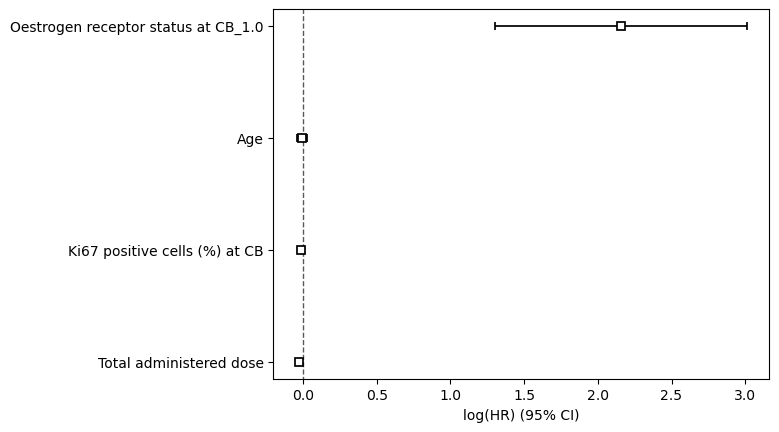

In [134]:
cph.plot()

In [272]:
fit_data

cph = CoxPHFitter()
cph.fit(fit_data, duration_col='Survival days', event_col='Regional LN recurrence')

<lifelines.CoxPHFitter: fitted with 2376 total observations, 2349 right-censored observations>

In [269]:
fit_data_2 = fit_data.copy()
fit_data_2['Regional LN recurrence'] = 0

In [273]:
r = cph.compute_residuals(fit_data, 'deviance')

c:\Users\marti\anaconda3\envs\survival-env\Lib\site-packages\lifelines\fitters\coxph_fitter.py:1906: RuntimeWarning: divide by zero encountered in log
  log_term = np.where((E.values - rmart.values) <= 0, 0, E.values * log(E.values - rmart.values))
c:\Users\marti\anaconda3\envs\survival-env\Lib\site-packages\lifelines\fitters\coxph_fitter.py:1906: RuntimeWarning: invalid value encountered in multiply
  log_term = np.where((E.values - rmart.values) <= 0, 0, E.values * log(E.values - rmart.values))


In [247]:
r.loc[r['Regional LN recurrence'], 'martingale'] -= 1

<Axes: xlabel='Survival days', ylabel='deviance'>

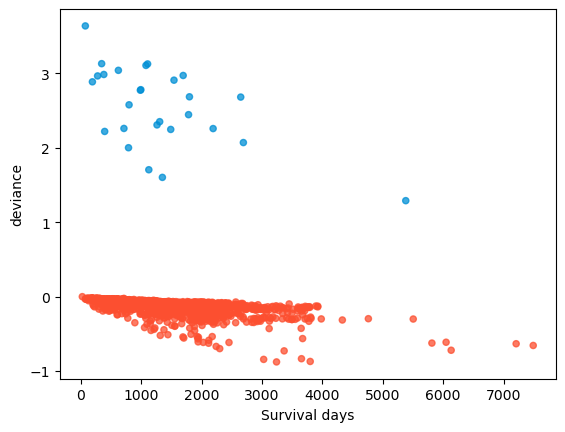

In [274]:
r.plot.scatter(
    x='Survival days', y='deviance', c=np.where(r['Regional LN recurrence'], '#008fd5', '#fc4f30'),
    alpha=0.75
)